In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
import pandas as pd
import numpy as np
import json
import random
from xgboost import XGBRegressor, XGBClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, mean_squared_error, accuracy_score
from sklearn.model_selection import GridSearchCV, train_test_split
from imblearn.under_sampling import RandomUnderSampler
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from src.modelos import MLP_regresion, MLP_clasificacion
from src.utils import df_features_to_numpy, df_target_to_numpy, run_experiment_pytorch_clasificacion, run_experiment_pytorch_regresion, permutation_importance_pytorch
from src.splitting import split_estratificado_autor
from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion
from src.graficos import plot_confusion_matrix, plot_learning_curves_xgboost_regression, plot_learning_curves_xgboost_classification, plot_feature_importance_xgb, plot_learning_curves_randomforest_regression, plot_learning_curves_randomforest_classification, plot_feature_importance_rf, plot_feature_importance_pytorch

# Cargo el dataset ya procesado

In [4]:
#LEO TEST
chunks_test = pd.read_json("set_test_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_test:
    chunk_list.append(chunk)
df_test = pd.concat(chunk_list, ignore_index=True)

#LEO VAL
chunks_val = pd.read_json("set_val_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_val:
    chunk_list.append(chunk)
df_val = pd.concat(chunk_list, ignore_index=True)

#LEO TRAIN
chunks_train = pd.read_json("set_train_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_train:
    chunk_list.append(chunk)
df_train = pd.concat(chunk_list, ignore_index=True)

## Preparacion de los datos
Elegimos las features con las que nos vamos a quedar para esta etapa. Convertimos los datafreames a arrays de numpy, y escalamos los datos. 

In [5]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series", "publication_year", "num_pages", 'AUDIO', 'COMIC', 'EBOOK', 'HARDCOVER', 'OTHER', 'PAPERBACK', "language_code_ang", "language_code_en", "language_code_en-CA", "language_code_en-GB", "language_code_en-US", "language_code_eng", "language_code_enm", "language_code_gem", "language_code_sco", "cantidad_generos"] + generos #'UNKNOWN' la saco por el one hot en regresion

#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val, df_test]
y_train_regresion, y_val_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
y_train_clasificacion, y_val_clasificacion, y_test_clasificacion = df_target_to_numpy("estrellas", dfs)
X_train, X_val, X_test = df_features_to_numpy(features, dfs)

#estandarizo los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train
#TODO: escalar el X_test

### Variables que necesito para hacer grid search
Creo un subset estratificado (por estrellas) de 100mil muestras. Este subset nos sirve para hacer un grid search manteniendo las distribuciones pero sin que tome mucho tiempo ni capacidad de computo. 

In [5]:
#variables que necesito para grid search, tanto para random forest como para xgboost
X_sub, _, y_sub_regresion, _, y_sub_clasificacion, _ = train_test_split(X_train_scaled, y_train_regresion, y_train_clasificacion, train_size=100000, stratify=y_train_clasificacion, random_state=42)

parametros_grid_search_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

parametros_grid_search_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

parametros_grid_search_rn = {
    "capas_ocultas": [[128, 64], [256, 128], [256, 128, 64]],
    "dropout": [0.0, 0.2, 0.4],
    "lr": [0.01, 0.001, 0.0001],
    "funcion_activacion": [nn.ReLU, nn.LeakyReLU]
}

### Preparo los datos que voy a usar en los modelos cuando quiera usar tecnicas de rebalanceo

In [6]:
#Hago undersampling para los datos de train, uso el valor optimo encontrado en ModeloBase
cant_datos_deseada = {4: 225000}
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada, random_state = 42)
X_train_undersampling, y_train_undersampling = undersampling.fit_resample(X_train_scaled, y_train_clasificacion) 

#Hago undersampling para el subset usado en grid search
cant_datos_deseada_sub = {4: 50000} 
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada_sub, random_state = 42)
X_sub_undersampling, y_sub_clasificacion_undersampling = undersampling.fit_resample(X_sub, y_sub_clasificacion) 

El valor optimo encontrado en ModeloBase para la cantidad de datos deseada de la clase 4 post undersampling es 225000, lo que corresponde aproximadamente al 50% del dataset de train. <br>
Entonces, para la cantidad de datos deseada de la clase 4 para el subset de grid search, tomo como valor el 50% de los datos de X_sub (subset de train). Para el subset elijo 100000 muestras, por lo que la cantidad de datos deseada de la clase 4 post undersampling va a ser 50000. 

Guia de variables para clasificacion:
<br> <br>
**X_sub**: conjunto utilizado en grid search sin undersampling <br>
**X_sub_undersampling**: conjunto utilizado en grid search con undersampling <br>
**X_train_scaled**: conjunto utilizado en el entrenamiento del modelo sin undersampling <br>
**X_train_undersampling**: conjunto utilizado en el entrenamiento del modelo con undersampling <br>
<br>
**y_sub_clasificacion**: conjunto utilizado en grid search sin undersampling <br>
**y_sub_clasificacion_undersampling**: conjunto utilizado en grid search con undersampling <br>
**y_train_clasificacion**: conjunto utilizado en el entrenamiento del modelo sin undersampling <br>
**y_train_undersampling**: conjunto utilizado en el entrenamiento del modelo con undersampling <br>

## Random Forest con features basicas - Regresion

Grid Search: tomo una muestra de 100 mil datos para encontrar los mejores hiperparametros, una vez encontrados estos valores reentreno con todos los datos

In [7]:
RandomForestGridSearchRegresion = RandomForestRegressor(random_state=42)
grid = GridSearchCV(estimator = RandomForestGridSearchRegresion, param_grid = parametros_grid_search_rf, cv = 3, scoring="r2", n_jobs=-1, verbose=2)
grid.fit(X_sub, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Mejores parametros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 300}
Mejor R² CV: 0.2025866763971781


In [8]:
modeloRandomForestRegresion = RandomForestRegressor(**mejores_parametros, random_state = 42)
modeloRandomForestRegresion.fit(X_train_scaled, y_train_regresion)

y_pred_train_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_train_scaled)
y_pred_val_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloRandomForestRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloRandomForestRegresion, y_val_regresion)
tabla_metricas_rf_regresion = tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"])
print(tabla_metricas_rf_regresion)

         Train  Validation
MSE   0.094731    0.111398
RMSE  0.307785    0.333763
MAE   0.235822    0.256908
R²    0.330143    0.214624


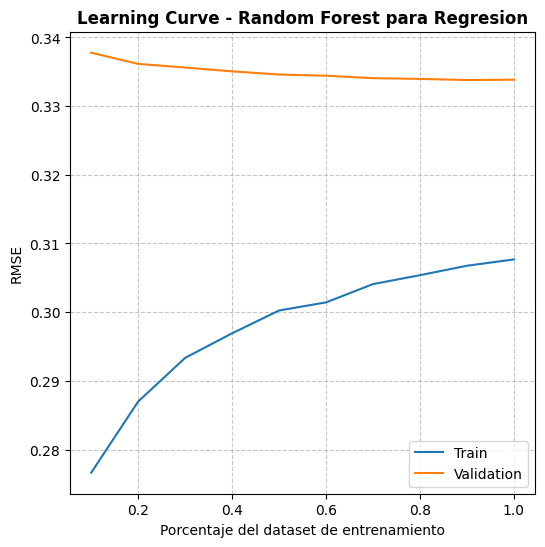

In [9]:
plot_learning_curves_randomforest_regression(X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, **mejores_parametros)

Analizamos la feature importance:

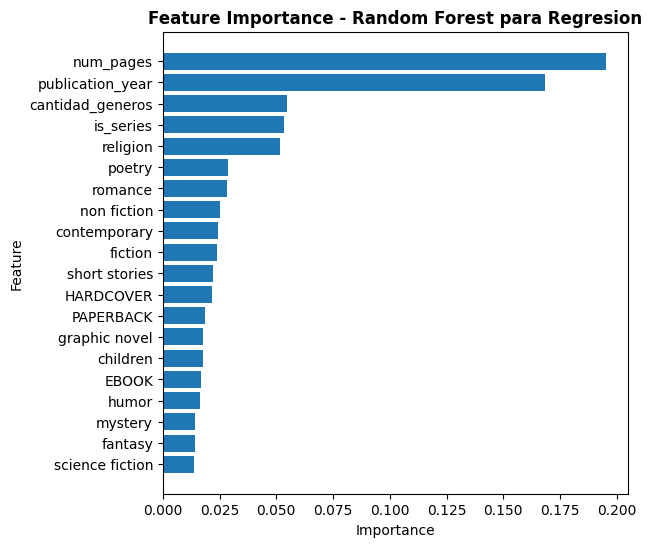

In [10]:
importancias_coef_rf_reg = pd.DataFrame({"feature": features, "importance": modeloRandomForestRegresion.feature_importances_})
importancias_coef_rf_reg = importancias_coef_rf_reg.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_reg, "para Regresion")

Observando las metricas y la learning curve, notamos que el modelo generaliza bastante bien, obtenemos valores parecidos en train y validation. <br> Los errores obtenidos no son grandes, pero tampoco ideales. Poniendo esto en relacion con la feature importance, notamos que las features no aportan demasiada informacion, lo que podria explicar los resultados de las metricas. 

## Random Forest con features basicas - Clasificacion

Para tratar con el desbalanceo de clases, implemento dos metodos. En primer lugar cost re-weight + undersampling (con los pesos y proporciones optimos encontrados en Modelo_Base), y despues unicamente cost re-weight.

In [11]:
pesos_undersampling_cost = {1:8, 2:10, 3:2, 4:1, 5:3}
pesos_cost = {1:8, 2:2, 3:2, 4:1, 5:5}

def grid_search_rf_clasificacion(pesos, X, y):
    RandomForestGridSearchClasificacion = RandomForestClassifier(random_state = 42, class_weight = pesos)

    #uso las mismas opciones de hiperparametros q use en regresion, y los mismos indices para obtener los subconjuntos
    grid = GridSearchCV(estimator = RandomForestGridSearchClasificacion, param_grid = parametros_grid_search_rf, cv = 3, scoring = "f1_macro", n_jobs = -1, verbose = 2)
    grid.fit(X, y)

    mejores_parametros = grid.best_params_
    print(f"Mejores parametros: {mejores_parametros}")
    print(f"Mejor F1 CV: {grid.best_score_}")
    return mejores_parametros

def evaluar_modelo_rf_clasificacion(mejores_parametros, pesos, X_train, y_train, X_val, y_val):
    modeloRandomForestClasificacion = RandomForestClassifier(**mejores_parametros, random_state = 42, class_weight = pesos)
    modeloRandomForestClasificacion.fit(X_train, y_train)

    y_pred_train_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_train))
    y_pred_val_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_val))

    metricas_train = evaluar_metricas_clasificacion(y_pred_train_modeloRandomForestClasificacion, y_train)
    metricas_val = evaluar_metricas_clasificacion(y_pred_val_modeloRandomForestClasificacion, y_val)
    tabla_metricas_rf_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
    print(tabla_metricas_rf_clasificacion)

    cm_train = confusion_matrix(y_train, y_pred_train_modeloRandomForestClasificacion)
    cm_val = confusion_matrix(y_val, y_pred_val_modeloRandomForestClasificacion)
    plot_confusion_matrix(cm_train, cm_val)
    return tabla_metricas_rf_clasificacion, modeloRandomForestClasificacion

### Cost + undersampling

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Mejores parametros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
Mejor F1 CV: 0.3009018796004636
              Train  Validation
Accuracy   0.781296    0.768372
Precision  0.788691    0.298320
Recall     0.399284    0.288285
F1         0.453009    0.292471


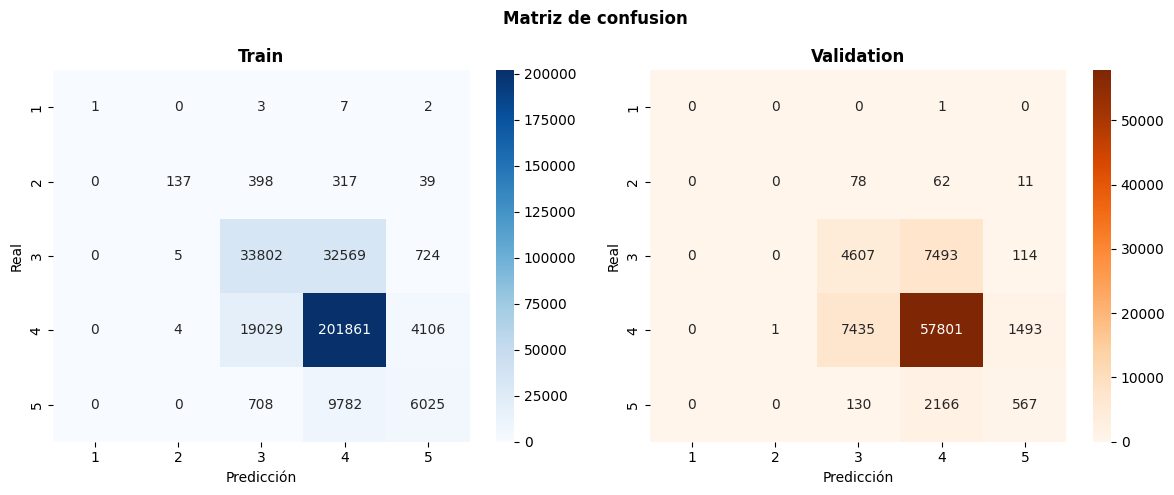

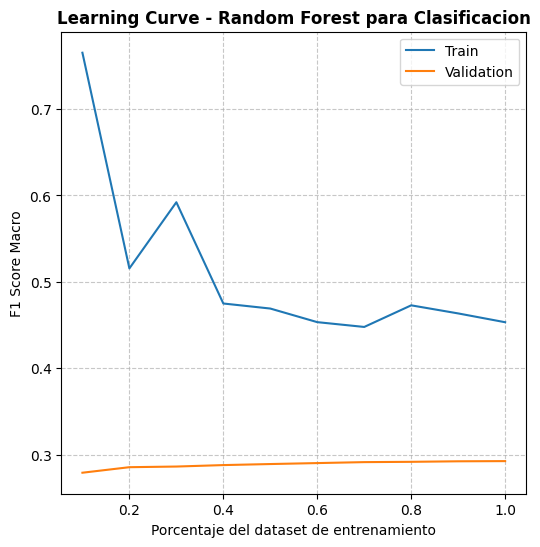

In [12]:
mejores_parametros = grid_search_rf_clasificacion(pesos_undersampling_cost, X_sub_undersampling, y_sub_clasificacion_undersampling)
tabla_metricas_rf_clasificacion_undersampling_cost, modeloRandomForestClasificacion = evaluar_modelo_rf_clasificacion(mejores_parametros, pesos_undersampling_cost, X_train_undersampling, y_train_undersampling, X_val_scaled, y_val_clasificacion)
plot_learning_curves_randomforest_classification(X_train_undersampling, y_train_undersampling, X_val_scaled, y_val_clasificacion, pesos = pesos_undersampling_cost, **mejores_parametros)

Analizamos la feature importance:

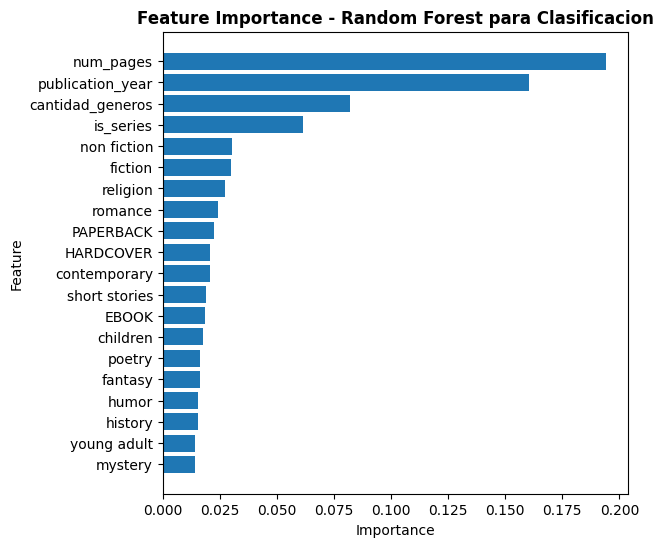

In [13]:
importancias_coef_rf_clasf = pd.DataFrame({"feature": features, "importance": modeloRandomForestClasificacion.feature_importances_})
importancias_coef_rf_clasf = importancias_coef_rf_clasf.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_clasf, "para Clasificacion")

Observando las matrices de confusion, notamos que el modelo logra predecir algunas veces las clases 1 y 2, pero los numeros siguen siendo bajos. <br>
Analizando las metricas, notamos que el modelo generaliza bastante bien para las clases mayoritarias, pero pierde capacidad para identificar correctamente las clases minoritarias, especialmente cuando se evalua el modelo con datos no vistos. Esto concuerda con los resultados de precision, recall y f1. El accuracy permanece constante por el desbalance de clases. 

### Cost sin undersampling

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Mejores parametros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 300}
Mejor F1 CV: 0.2552048188988588
              Train  Validation
Accuracy   0.827676    0.804231
Precision  0.381044    0.319310
Recall     0.302658    0.258206
F1         0.318246    0.267348


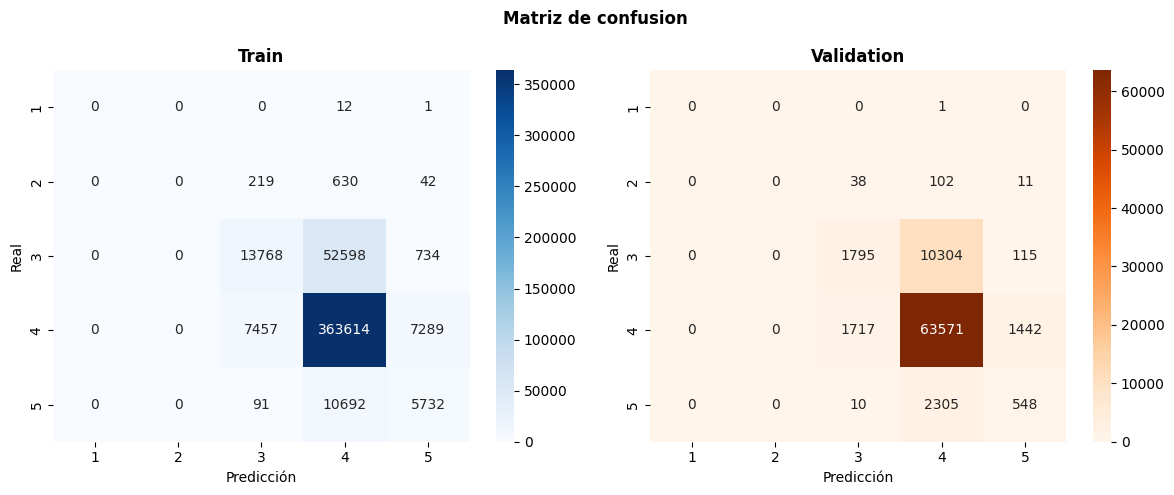

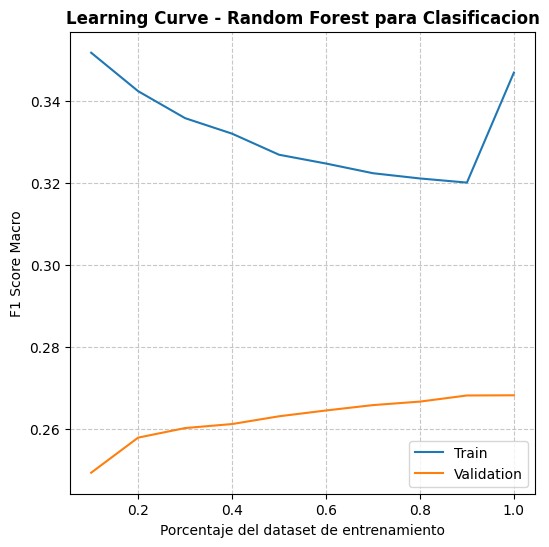

In [14]:
mejores_parametros = grid_search_rf_clasificacion(pesos_cost, X_sub, y_sub_clasificacion)
tabla_metricas_rf_clasificacion_cost, modeloRandomForestClasificacion = evaluar_modelo_rf_clasificacion(mejores_parametros, pesos_cost, X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion)
plot_learning_curves_randomforest_classification(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, pesos = pesos_cost, **mejores_parametros)

Analizamos la feature importance

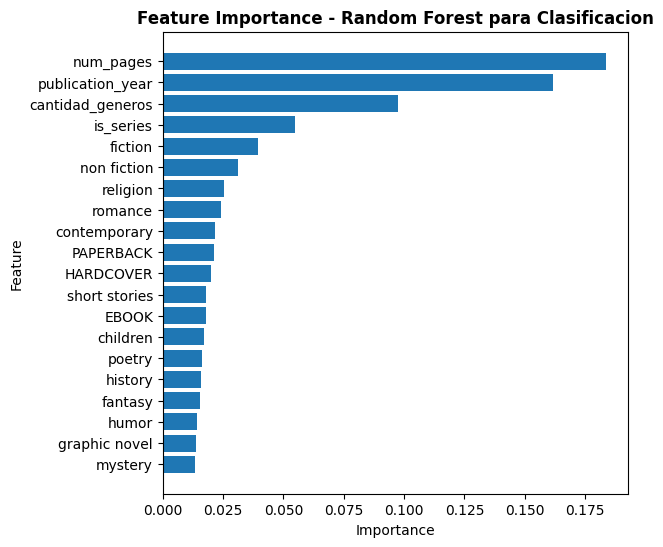

In [15]:
importancias_coef_rf_clasf = pd.DataFrame({"feature": features, "importance": modeloRandomForestClasificacion.feature_importances_})
importancias_coef_rf_clasf = importancias_coef_rf_clasf.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_clasf, "para Clasificacion")

Con este rebalanceo obtenemos una mejor generalizacion y un mejor resultado en accuracy, pero peores valores de f1, accuracy y precision. 

## XGBoost con features basicas - Regresion

Empiezo con grid search para buscar los mejores hiperparametros

In [17]:
XGBoostGridSearchRegresion = XGBRegressor(random_state = 42)
grid = GridSearchCV(estimator = XGBoostGridSearchRegresion, param_grid = parametros_grid_search_xgb, cv = 3, scoring = "r2", n_jobs = -1, verbose = 2)
grid.fit(X_sub, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

Fitting 3 folds for each of 108 candidates, totalling 324 fits
Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.8}
Mejor R² CV: 0.21235470875572413


In [18]:
#subsample --> en cada arbol solo usa una fraccion de las filas (muestras) --> ayuda a descorrelacionar
#colsample_bytree --> solo usa una fraccion de las columnas (features) --> ayuda a descorrelacionar
modeloXGBoostRegresion = XGBRegressor(**mejores_parametros, objective = "reg:squarederror", random_state = 42) #MInimiza MSE
modeloXGBoostRegresion.fit(X_train_scaled, y_train_regresion) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

y_pred_train_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_train_scaled)
y_pred_val_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloXGBoostRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloXGBoostRegresion, y_val_regresion)
tabla_metricas_xgboost_regresion = tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"])
print(tabla_metricas_xgboost_regresion)

         Train  Validation
MSE   0.107125    0.109674
RMSE  0.327299    0.331170
MAE   0.251485    0.254547
R²    0.242508    0.226777


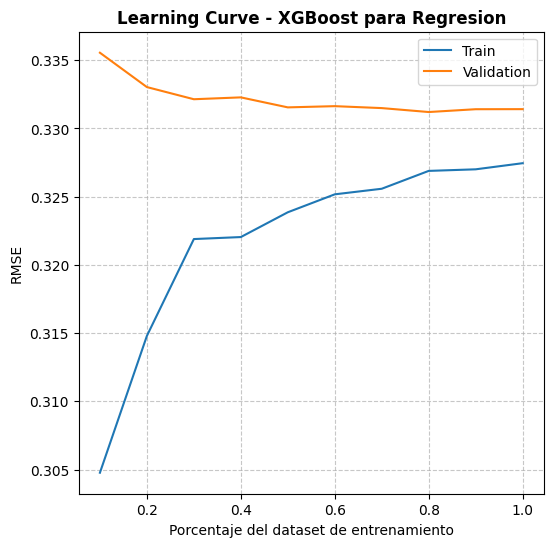

In [19]:
plot_learning_curves_xgboost_regression(X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, **mejores_parametros)

Analizamos las feature importance:

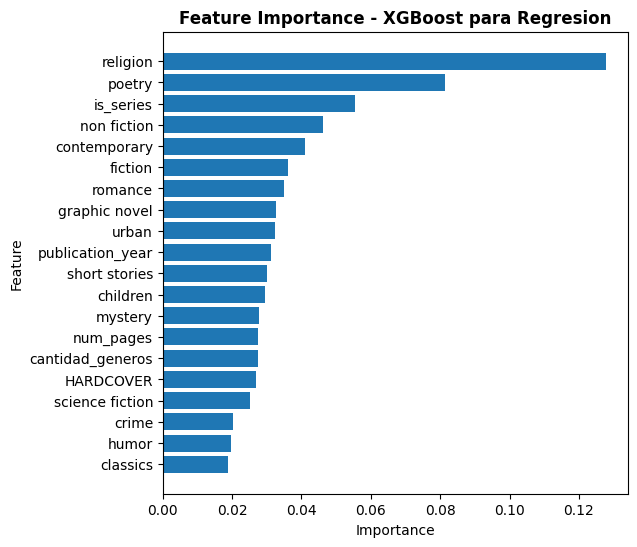

In [20]:
importancias_coef_xgb_reg = pd.DataFrame({"feature": features, "importance": modeloXGBoostRegresion.feature_importances_})
importancias_coef_xgb_reg = importancias_coef_xgb_reg.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_reg, "para Regresion")

Con XGBoost obtenemos resultados muy similares a los que habiamos tenido con Random Forest. Se logra una buena generalizacion pero nuestras features no logran explicar correctamente la variabilidad del rating. 

## XGBoost con features basicas - Clasificacion

XGBoost solo trabaja con clases empezando desde 0, (aunque nuestras estrellas vayan de 1 a 5). Para poder entrenar con este modelo, transformo temporalmente el target restando 1. Luego, para volver a las clases normales, sumo 1 a la prediccion.

In [ ]:
#transformaciones temporales
y_sub_undersampling_temp = y_sub_clasificacion_undersampling - 1
y_sub_temp = y_sub_clasificacion - 1
y_train_undersampling_temp = y_train_undersampling - 1
y_train_temp = y_train_clasificacion - 1

#exactamente los mismos pesos que antes pero con las clases - 1
pesos_undersampling_cost_xgb = {0:8, 1:10, 2:2, 3:1, 4:3}
pesos_cost_xgb = {0:8, 1:2, 2:2, 3:1, 4:5}

In [ ]:
def grid_search_xgb_clasificacion(pesos, X, y):
    pesos_transformados_sub = np.array([pesos[y_i] for y_i in y])
    XGBoostGridSearchClasificacion = XGBClassifier(objective = "multi:softmax", num_class = 5, random_state = 42) 

    #uso los mismos indices para obtener los subconjuntos
    grid = GridSearchCV(estimator = XGBoostGridSearchClasificacion, param_grid = parametros_grid_search_xgb, cv = 3, scoring = "f1_macro", n_jobs = -1, verbose = 2)
    grid.fit(X, y, sample_weight = pesos_transformados_sub)

    mejores_parametros = grid.best_params_
    print(f"Mejores parametros: {mejores_parametros}")
    print(f"Mejor F1 CV: {grid.best_score_}")
    return mejores_parametros

def evaluar_modelo_xgb_clasificacion(mejores_parametros, pesos, X_train, y_train, X_val, y_val):
    pesos_transformados_train = np.array([pesos[y] for y in y_train])
    modeloXGBoostClasificacion = XGBClassifier(**mejores_parametros, objective = "multi:softmax", num_class = 5, random_state = 42) 
    modeloXGBoostClasificacion.fit(X_train, y_train, sample_weight = pesos_transformados_train) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

    y_pred_train = (modeloXGBoostClasificacion.predict(X_train))
    y_pred_val = (modeloXGBoostClasificacion.predict(X_val))
    #volvemos a las clases originales sumando 1
    y_train = y_train + 1
    y_pred_train_modeloXGBoostClasificacion = y_pred_train + 1
    y_pred_val_modeloXGBoostClasificacion = y_pred_val + 1

    #calculo las metricas usando las clases originales entre 1 y 5
    metricas_train = evaluar_metricas_clasificacion(y_pred_train_modeloXGBoostClasificacion, y_train)
    metricas_val = evaluar_metricas_clasificacion(y_pred_val_modeloXGBoostClasificacion, y_val)
    tabla_metricas_xgboost_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
    print(tabla_metricas_xgboost_clasificacion)

    cm_train = confusion_matrix(y_train, y_pred_train_modeloXGBoostClasificacion)
    cm_val = confusion_matrix(y_val, y_pred_val_modeloXGBoostClasificacion)
    plot_confusion_matrix(cm_train, cm_val)
    return tabla_metricas_xgboost_clasificacion, modeloXGBoostClasificacion

### Cost + undersampling

X: (68259, 47)
y: (68259,)
sample_weight: (68259,)
Fitting 3 folds for each of 108 candidates, totalling 324 fits
Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200, 'subsample': 0.8}
Mejor F1 CV: 0.3300120112323454
              Train  Validation
Accuracy   0.723303    0.734379
Precision  0.643206    0.305758
Recall     0.590829    0.314367
F1         0.595678    0.302952


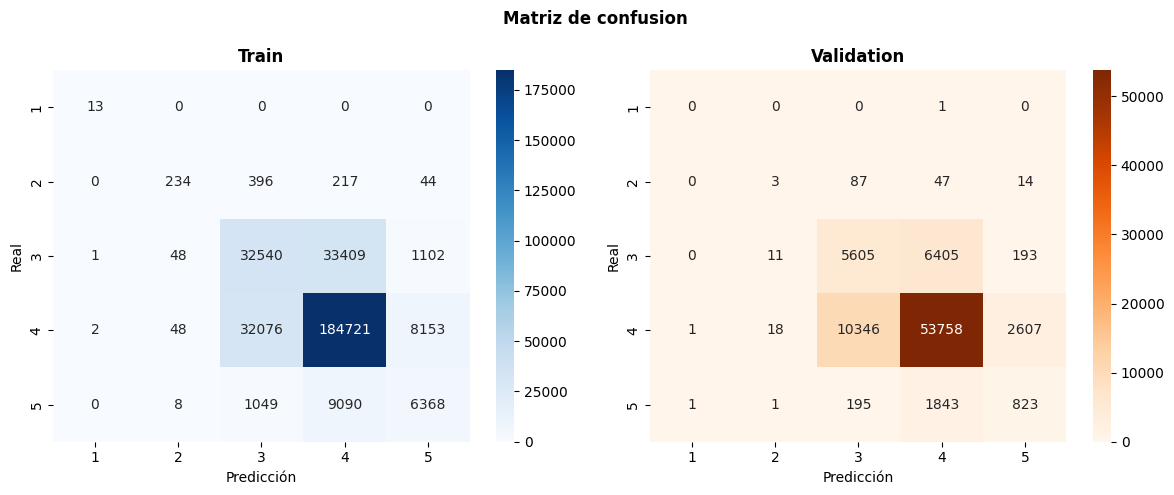

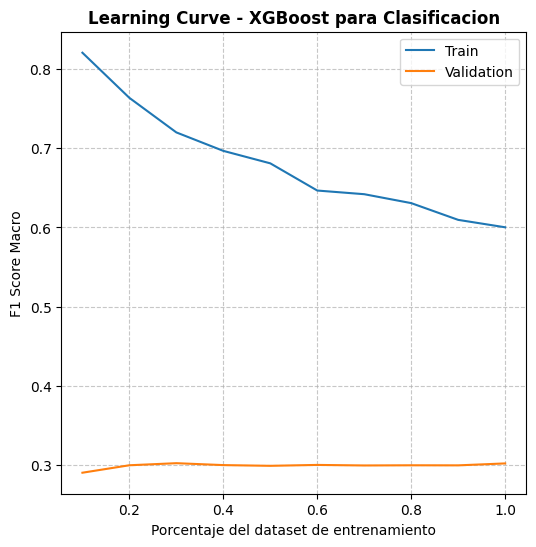

In [ ]:
mejores_parametros = grid_search_xgb_clasificacion(pesos_undersampling_cost_xgb, X_sub_undersampling, y_sub_undersampling_temp)
tabla_metricas_xgb_clasificacion_undersampling_cost, modeloXGBoostClasificacion = evaluar_modelo_xgb_clasificacion(mejores_parametros, pesos_undersampling_cost_xgb, X_train_undersampling, y_train_undersampling_temp, X_val_scaled, y_val_clasificacion)
plot_learning_curves_xgboost_classification(X_train_undersampling, y_train_undersampling, X_val_scaled, y_val_clasificacion, pesos = pesos_undersampling_cost_xgb, **mejores_parametros)

Analizamos las feature importance:

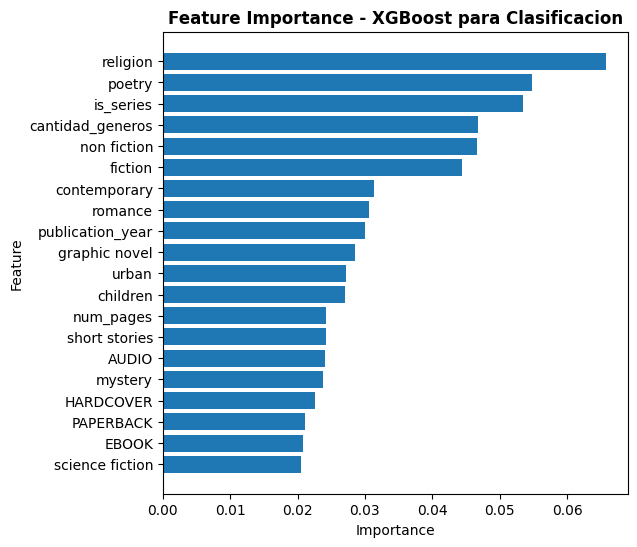

In [33]:
importancias_coef_xgb_clasf = pd.DataFrame({"feature": features, "importance": modeloXGBoostClasificacion.feature_importances_})
importancias_coef_xgb_clasf = importancias_coef_xgb_clasf.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_clasf, "para Clasificacion")

Al igual que en random forest, con cost y undersampling se obtienen muy buenas metricas en train, pero estas decaen al aplicarlas a datos nuevos. Sin embargo, estos ultimos resultados se mantienen similares a los de otros modelos. 

### Cost sin undersampling

<class 'numpy.ndarray'> (462879, 47)
<class 'numpy.ndarray'> (462879,)
<class 'numpy.ndarray'> (462879,)
[3 1 3 3 3]
              Train  Validation
Accuracy   0.793121    0.786564
Precision  0.626983    0.305011
Recall     0.498700    0.286874
F1         0.472965    0.288421


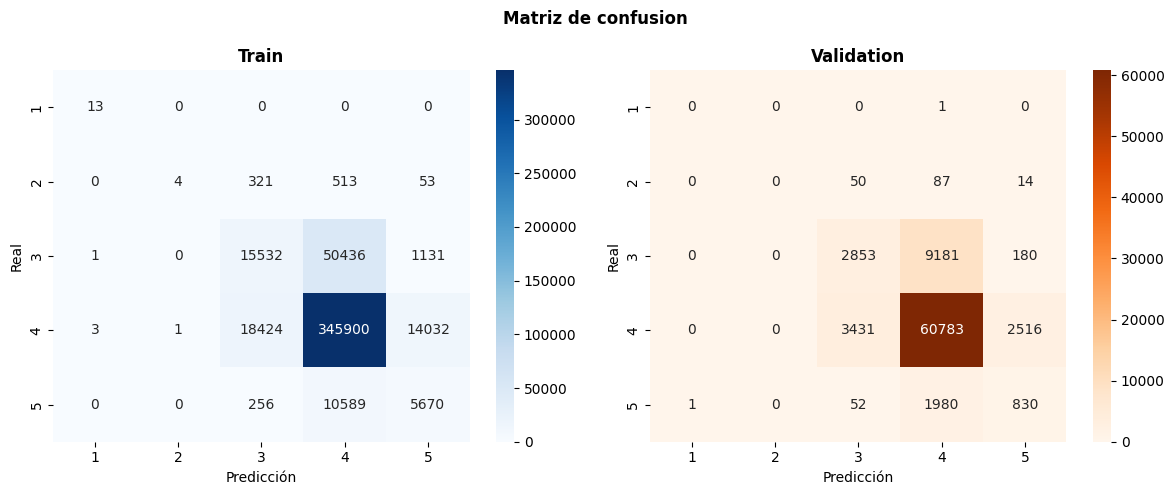

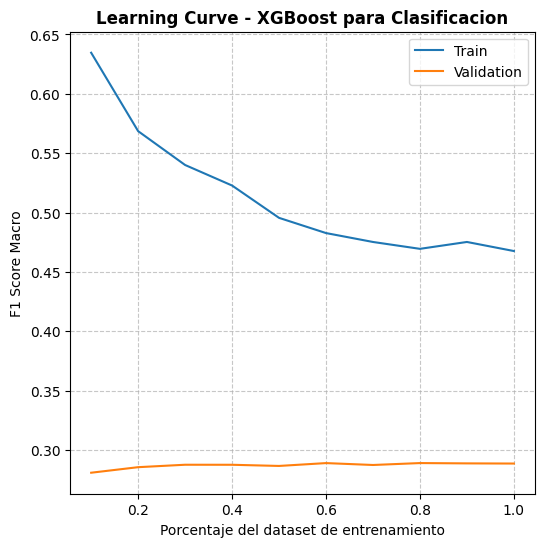

In [ ]:
mejores_parametros = grid_search_xgb_clasificacion(pesos_cost_xgb, X_sub, y_sub_temp)
tabla_metricas_xgb_clasificacion_cost, modeloXGBoostClasificacion = evaluar_modelo_xgb_clasificacion(mejores_parametros, pesos_cost_xgb, X_train_scaled, y_train_temp, X_val_scaled, y_val_clasificacion)
plot_learning_curves_xgboost_classification(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, pesos = pesos_cost_xgb, **mejores_parametros)

Analizamos las feature importance:

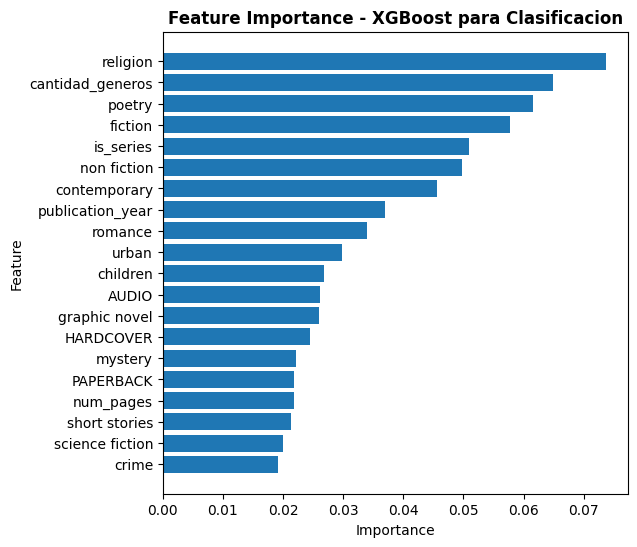

In [41]:
importancias_coef_xgb_clasf = pd.DataFrame({"feature": features, "importance": modeloXGBoostClasificacion.feature_importances_})
importancias_coef_xgb_clasf = importancias_coef_xgb_clasf.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_clasf, "para Clasificacion")

Obtenemos el mismo problema que con la anterior tecnica de rebalanceo. 

## Red neuronal con features basicas - Regresion

In [42]:
if torch.cuda.is_available():
  device = "cuda"
else:
  device = "cpu"

Grid search

In [43]:
from src.utils import run_grid_search_pytorch_regresion

mejor_r2 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                modelo = MLP_regresion(input_size = X_sub.shape[1], hidden_layers=capas_ocultas, activation=activacion, dropout=dropout).to(device)
                r2 = run_grid_search_pytorch_regresion(modelo=modelo, learning_rate = lr, model_name="MLP Regresion", X_train=X_sub, y_train=y_sub_regresion, X_val=X_val_scaled, y_val=y_val_regresion, device=device, epochs=30)
                if r2 > mejor_r2:
                    mejor_r2 = r2
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

PyTorch: 100%|██████████| 30/30 [01:26<00:00,  2.89s/epoca, epoch=30]


Mejores parametros: {'capas_ocultas': [256, 128], 'dropout': 0.2, 'lr': 0.01, 'activacion': <class 'torch.nn.modules.activation.ReLU'>}


PyTorch: 100%|██████████| 100/100 [16:30<00:00,  9.90s/epoca, epoch=100]


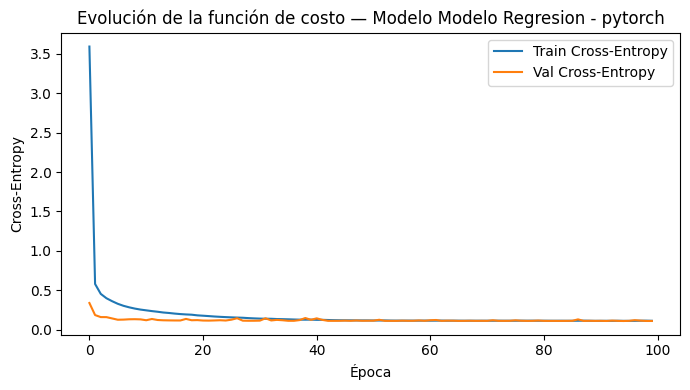

         Train  Validation
MSE   0.111728    0.112396
RMSE  0.334257    0.335256
MAE   0.256425    0.257215
R²    0.209961    0.207582


In [44]:
modelo_regresion = MLP_regresion(input_size = X_train_scaled.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_regresion(modelo_regresion, "Modelo Regresion", X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, device, learning_rate = mejores_parametros["lr"])
tabla_metricas_mlp_regresion = tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"])
print(tabla_metricas_mlp_regresion)

Las redes neuronales con pytorch no tienen un atributo para acceder a la feature importance, a diferencia de XGBoost o Random Forest. Para simular esto, se agarra por separado cada feature y se la mezcla (de esta manera se descorrelaciona la salida del modelo con esta feature). Despues, se predice con esa nueva feature y se evalua la diferencia con el X original. A mayor diferencia mayor impacto tiene la feature. 

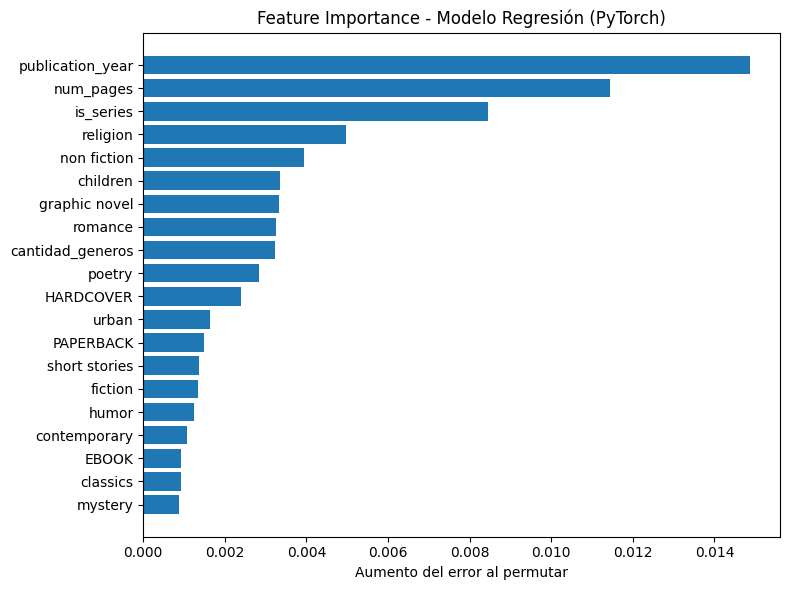

In [45]:
feature_importance_regresion = permutation_importance_pytorch(modelo_regresion, X_val_scaled, y_val_regresion, features, device,metric_fn=mean_squared_error, higher_is_better=False, n_repeats=10)
plot_feature_importance_pytorch(feature_importance_regresion, top_n=20, title="Feature Importance - Modelo Regresión (PyTorch)")

Las metricas resultan muy consistentes en train y validation, generaliza correctamente. Sin embargo, al igual que en random forest y xgboost, el R² se mantiene en 0.2, un valor bastante bajo. 

## Red neuronal con features basicas - Clasificacion

La red neuronal tambien necesita que las clases empiecen en 0, por lo que adentro de las funciones manejo los conjuntos de y restando 1, y luego sumando 1 a la prediccion. 

### Cost sin undersampling

In [46]:
from src.utils import run_grid_search_pytorch_clasificacion

mejor_f1 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                print(f"Probando: {capas_ocultas}, dropout={dropout}, lr={lr}, activacion={activacion.__name__}")
                modelo = MLP_clasificacion(input_size=X_sub.shape[1], hidden_layers=capas_ocultas, n_classes=5, activation=activacion, dropout=dropout).to(device)

                f1 = run_grid_search_pytorch_clasificacion(modelo=modelo, learning_rate=lr, model_name="MLP Clasificacion", X_train=X_sub, y_train=y_sub_clasificacion, X_val=X_val_scaled, y_val=y_val_clasificacion, device=device, epochs=30, pesos = pesos_cost)

                if f1 > mejor_f1:
                    mejor_f1 = f1
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

Probando: [128, 64], dropout=0.0, lr=0.01, activacion=ReLU


PyTorch: 100%|██████████| 30/30 [01:03<00:00,  2.13s/epoca, epoch=30]


Probando: [128, 64], dropout=0.0, lr=0.01, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [02:01<00:00,  4.04s/epoca, epoch=30]


Probando: [128, 64], dropout=0.0, lr=0.001, activacion=ReLU


...

Probando: [256, 128, 64], dropout=0.4, lr=0.0001, activacion=ReLU


PyTorch: 100%|██████████| 30/30 [01:16<00:00,  2.54s/epoca, epoch=30]


Probando: [256, 128, 64], dropout=0.4, lr=0.0001, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [01:15<00:00,  2.52s/epoca, epoch=30]


Mejores parametros: {'capas_ocultas': [256, 128, 64], 'dropout': 0.0, 'lr': 0.001, 'activacion': <class 'torch.nn.modules.activation.LeakyReLU'>}


PyTorch: 100%|██████████| 100/100 [16:41<00:00, 10.01s/epoca, epoch=100]


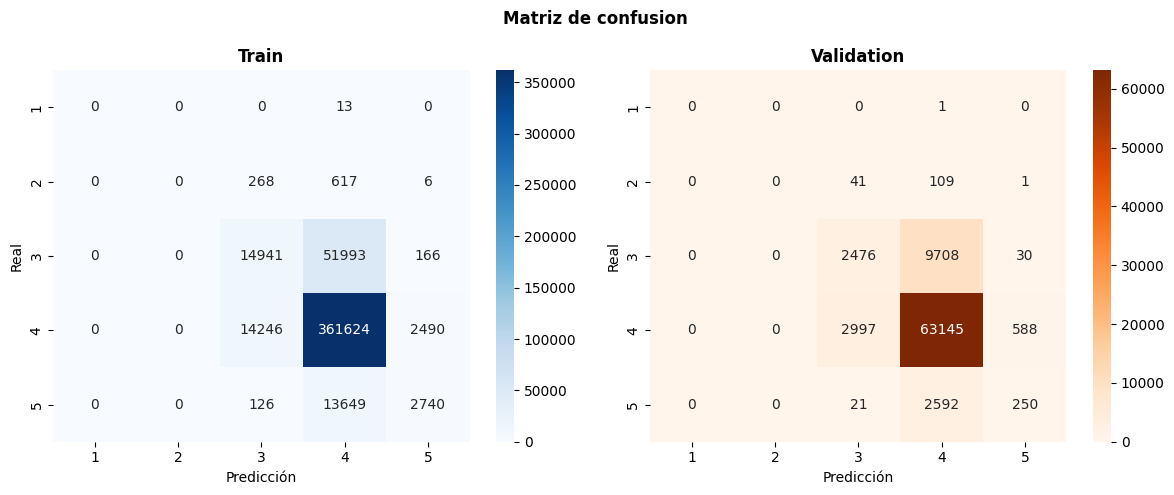

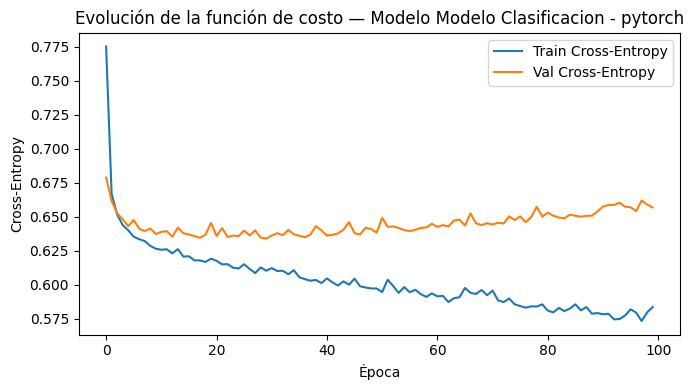

              Train  Validation
Accuracy   0.819447    0.803707
Precision  0.371486    0.314154
Recall     0.268869    0.247263
F1_score   0.291232    0.260113


In [47]:
modelo_clasificacion = MLP_clasificacion(input_size = X_train_scaled.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], n_classes = 5, activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_clasificacion(modelo_clasificacion, "Modelo Clasificacion", X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, device, learning_rate = mejores_parametros["lr"], pesos = pesos_cost)
tabla_metricas_mlp_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1_score"])
print(tabla_metricas_mlp_clasificacion)

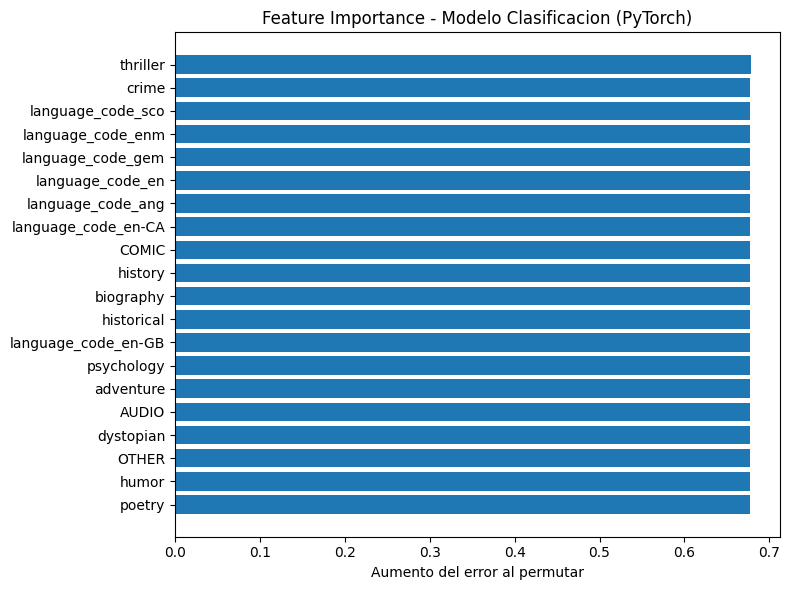

In [52]:
feature_importance_clasificacion = permutation_importance_pytorch(modelo_clasificacion, X_val_scaled, y_val_clasificacion, features, device, metric_fn=accuracy_score, higher_is_better=True, n_repeats=10, clasificacion = True)
plot_feature_importance_pytorch(feature_importance_clasificacion, top_n=20, title="Feature Importance - Modelo Clasificacion (PyTorch)")

Observamos de las matrices de confusion de este modelo que en ningun momento predice las clases minoritarias. No consideramos que sea un modelo adecuado. Los anteriores al menos predecian algunas veces estas clases. 

### Cost + undersampling

In [ ]:
#TODO: waiting

In [53]:
mejor_f1 = -np.inf
mejores_parametros = None

for capas_ocultas in parametros_grid_search_rn["capas_ocultas"]:
    for dropout in parametros_grid_search_rn["dropout"]:
        for lr in parametros_grid_search_rn["lr"]:
            for activacion in parametros_grid_search_rn["funcion_activacion"]:

                print(f"Probando: {capas_ocultas}, dropout={dropout}, lr={lr}, activacion={activacion.__name__}")
                modelo = MLP_clasificacion(input_size=X_sub.shape[1], hidden_layers=capas_ocultas, n_classes=5, activation=activacion, dropout=dropout).to(device)

                f1 = run_grid_search_pytorch_clasificacion(modelo=modelo, learning_rate=lr, model_name="MLP Clasificacion", X_train=X_sub_undersampling, y_train=y_sub_clasificacion_undersampling, X_val=X_val_scaled, y_val=y_val_clasificacion, device=device, epochs=30, pesos = pesos_undersampling_cost)

                if f1 > mejor_f1:
                    mejor_f1 = f1
                    mejores_parametros = {"capas_ocultas": capas_ocultas, "dropout": dropout, "lr": lr, "activacion": activacion}

print(f"\nMejores parametros: {mejores_parametros}")

Probando: [128, 64], dropout=0.0, lr=0.01, activacion=ReLU


PyTorch: 100%|██████████| 30/30 [00:51<00:00,  1.71s/epoca, epoch=30]


Probando: [128, 64], dropout=0.0, lr=0.01, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [00:52<00:00,  1.75s/epoca, epoch=30]


Probando: [128, 64], dropout=0.0, lr=0.001, activacion=ReLU


...

Probando: [256, 128, 64], dropout=0.4, lr=0.0001, activacion=ReLU


PyTorch: 100%|██████████| 30/30 [01:05<00:00,  2.19s/epoca, epoch=30]


Probando: [256, 128, 64], dropout=0.4, lr=0.0001, activacion=LeakyReLU


PyTorch: 100%|██████████| 30/30 [01:49<00:00,  3.65s/epoca, epoch=30]



Mejores parametros: {'capas_ocultas': [128, 64], 'dropout': 0.0, 'lr': 0.01, 'activacion': <class 'torch.nn.modules.activation.LeakyReLU'>}


PyTorch: 100%|██████████| 100/100 [13:23<00:00,  8.03s/epoca, epoch=100]


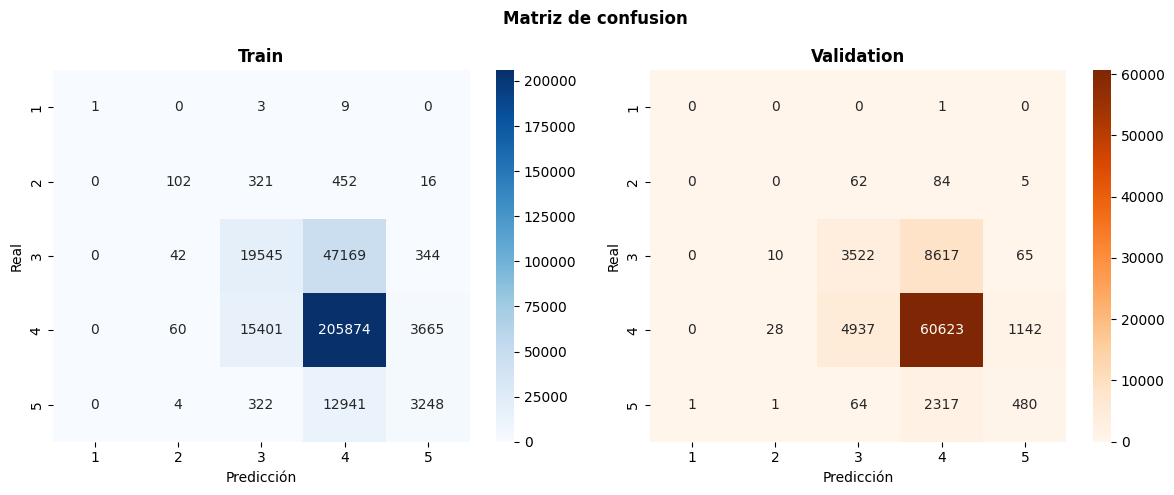

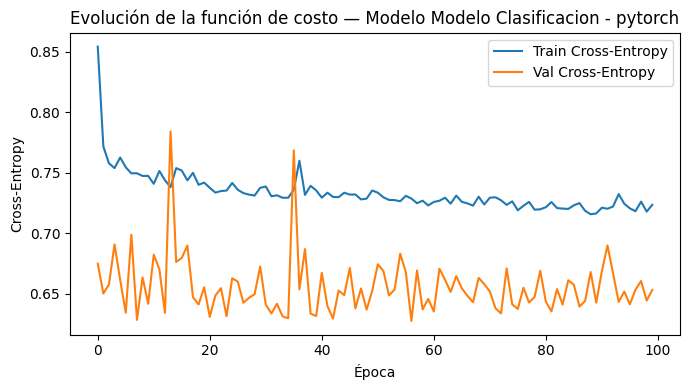

              Train  Validation
Accuracy   0.739115    0.788504
Precision  0.651756    0.308026
Recall     0.318870    0.272899
F1_score   0.364009    0.285132


In [54]:
modelo_clasificacion = MLP_clasificacion(input_size = X_train_scaled.shape[1], hidden_layers = mejores_parametros["capas_ocultas"], n_classes = 5, activation = mejores_parametros["activacion"], dropout = mejores_parametros["dropout"]).to(device)
metricas_train, metricas_val = run_experiment_pytorch_clasificacion(modelo_clasificacion, "Modelo Clasificacion", X_train_undersampling, y_train_undersampling, X_val_scaled, y_val_clasificacion, device, learning_rate = mejores_parametros["lr"], pesos = pesos_undersampling_cost)
tabla_metricas_mlp_clasificacion_undersampling = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1_score"])
print(tabla_metricas_mlp_clasificacion_undersampling)

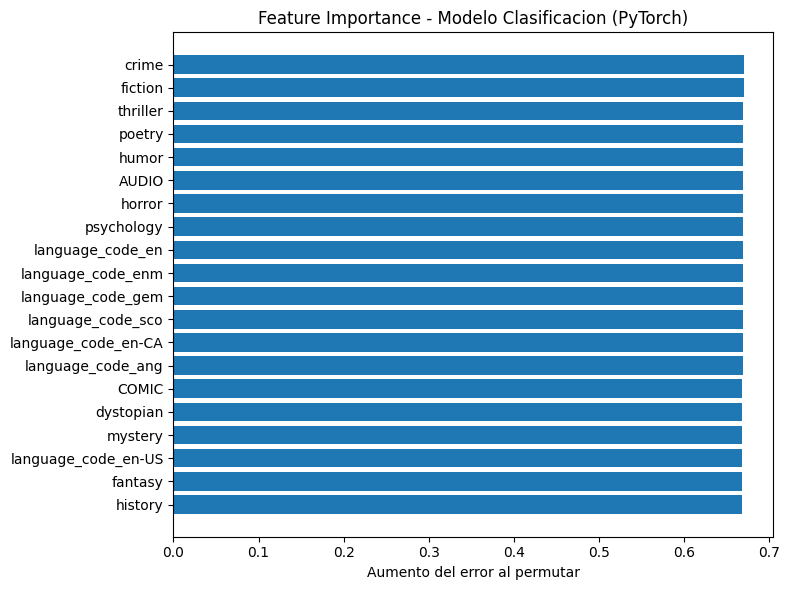

In [55]:
feature_importance_clasificacion = permutation_importance_pytorch(modelo_clasificacion, X_val_scaled, y_val_clasificacion, features, device, metric_fn=accuracy_score, higher_is_better=True, n_repeats=10, clasificacion = True)
plot_feature_importance_pytorch(feature_importance_clasificacion, top_n=20, title="Feature Importance - Modelo Clasificacion (PyTorch)")

Este modelo presenta metricas similares a las anteriores, con menos generalizacion en precision. 

# Comparacion de modelos

In [ ]:
print("Comparacion de tablas de metricas")

print("\nRANDOM FOREST")
print("Regresion")
display(tabla_metricas_rf_regresion)
print("\nClasificacion undersampling + cost")
display(tabla_metricas_rf_clasificacion_undersampling_cost)
print("\nClasificacion cost")
display(tabla_metricas_rf_clasificacion_cost)

print("\nXGBOOST")
print("Regresion")
display(tabla_metricas_xgboost_regresion)
print("\nClasificacion undersampling + cost")
display(tabla_metricas_xgb_clasificacion_undersampling_cost)
print("\nClasificacion cost")
display(tabla_metricas_xgb_clasificacion_cost)

print("\nRED NEURONAL")
print("Regresion")
display(tabla_metricas_mlp_regresion)
print("\nClasificacion undersampling + cost")
display(tabla_metricas_mlp_clasificacion)
print("\nClasificacion cost")
display(tabla_metricas_mlp_clasificacion_undersampling)

Comparacion de tablas de metricas

RANDOM FOREST
Regresion
         Train  Validation
MSE   0.094731    0.111398
RMSE  0.307785    0.333763
MAE   0.235822    0.256908
R²    0.330143    0.214624

Clasificacion undersampling + cost
              Train  Validation
Accuracy   0.781296    0.768372
Precision  0.788691    0.298320
Recall     0.399284    0.288285
F1         0.453009    0.292471

Clasificacion cost
              Train  Validation
Accuracy   0.827676    0.804231
Precision  0.381044    0.319310
Recall     0.302658    0.258206
F1         0.318246    0.267348

XGBOOST
Regresion
         Train  Validation
MSE   0.107125    0.109674
RMSE  0.327299    0.331170
MAE   0.251485    0.254547
R²    0.242508    0.226777

Clasificacion undersampling + cost
              Train  Validation
Accuracy   0.723303    0.734379
Precision  0.643206    0.305758
Recall     0.590829    0.314367
F1         0.595678    0.302952

Clasificacion cost
              Train  Validation
Accuracy   0.793121    0.786